# 教師用參考答案（不公開）

本檔集中收錄 NumPy、pandas、Matplotlib 與 scikit-learn 的小練習 1–8 完整題目與參考答案，並附課堂互動的教師講解；填空題保留原始挖空程式，作答區在 exercises.ipynb。
請由上往下執行，下方先備妥所需套件與模擬氣象資料。從專案根目錄或 `simplified` 目錄啟動皆可。
本檔為教師用解答，不屬於學生教材；學生教材不提供本檔連結。另收錄一般填空與模型練習的解答。

## 答案目錄

- [小練習 1：條件篩選與運算方向](#exercise-1)
- [小練習 2：比較兩個模型（程式填空）](#exercise-2)
- [小練習 3：依天氣類別填補資料（程式填空）](#exercise-3)
- [小練習 4：天氣類別摘要報表（程式填空）](#exercise-4)
- [小練習 5：把左右子圖改成上下子圖（程式填空）](#exercise-5)
- [小練習 6：比較兩組氣溫分布（程式填空）](#exercise-6)
- [小練習 7：加入是否下雨的相關係數熱圖（程式填空）](#exercise-7)
- [小練習 8：學習另一條直線（程式填空）](#exercise-8)

- [課堂互動：換個情境，你會怎麼判斷？](#classroom-discussion)


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

data_path = Path('data/weather_sample.csv')
if not data_path.exists():
    data_path = Path('simplified/data/weather_sample.csv')
df = pd.read_csv(data_path)


<a id="exercise-1"></a>

## 小練習 1：條件篩選與運算方向（程式填空）

來源：[numpy-基本功能.ipynb](./numpy-基本功能.ipynb)


### 題目

篩出第一欄至少 25、第二欄至少 75 的樣本與標籤，再分別計算各特徵、各樣本的平均。

請補上 `____`，保留固定資料與所有 print，不可直接寫死預期結果。NumPy 題請先匯入 `numpy as np`；pandas 題沿用教材讀入、尚未填補的原始 `df`。

**預期輸出（逐行比對）：**

```text
selected_X: [[25.0, 75.0], [32.0, 85.0]]
selected_y: [1, 0]
feature_mean: [28.5, 80.0]
sample_mean: [50.0, 58.5]
```

```python
X = np.array([[18, 90], [25, 75], [40, 60], [32, 85]], dtype=float)
y = np.array([0, 1, 1, 0])
mask = (X[:, 0] >= ____) & (X[:, 1] >= ____)
selected_X = X[____]
selected_y = y[____]
feature_mean = selected_X.mean(axis=____)
sample_mean = selected_X.mean(axis=____)
print('selected_X:', selected_X.tolist())
print('selected_y:', selected_y.tolist())
print('feature_mean:', feature_mean.tolist())
print('sample_mean:', sample_mean.tolist())
```


### 參考答案


In [2]:
X = np.array([[18, 90], [25, 75], [40, 60], [32, 85]], dtype=float)
y = np.array([0, 1, 1, 0])
mask = (X[:, 0] >= 25) & (X[:, 1] >= 75)
selected_X = X[mask]
selected_y = y[mask]
feature_mean = selected_X.mean(axis=0)
sample_mean = selected_X.mean(axis=1)
print('selected_X:', selected_X.tolist())
print('selected_y:', selected_y.tolist())
print('feature_mean:', feature_mean.tolist())
print('sample_mean:', sample_mean.tolist())


selected_X: [[25.0, 75.0], [32.0, 85.0]]
selected_y: [1, 0]
feature_mean: [28.5, 80.0]
sample_mean: [50.0, 58.5]


依序填入 `25`、`75`、`mask`、`mask`、`0`、`1`。同一個 mask 保持 X／y 對應；axis=0 跨樣本、axis=1 跨特徵。


<a id="exercise-2"></a>

## 小練習 2：比較兩個模型（程式填空）

來源：numpy-基本功能.ipynb


### 題目

補完程式，計算模型 A、B 各自的準確率，並找出**兩個模型都判錯**的樣本索引。
只填 `____`，不改資料與 print，也不可直接填入結果。

**預期輸出：**

```text
accuracy_a: 0.5
accuracy_b: 0.67
both_wrong: [2]
```

```python
y = np.array([1, 0, 1, 1, 0, 0])
pred_a = np.array([1, 1, 0, 1, 0, 1])
pred_b = np.array([1, 0, 0, 1, 1, 0])

correct_a = ____
correct_b = ____
both_wrong = ____

print('accuracy_a:', round(float(correct_a.mean()), 2))
print('accuracy_b:', round(float(correct_b.mean()), 2))
print('both_wrong:', np.where(both_wrong)[0].tolist())
```


### 參考答案


In [3]:
y = np.array([1, 0, 1, 1, 0, 0])
pred_a = np.array([1, 1, 0, 1, 0, 1])
pred_b = np.array([1, 0, 0, 1, 1, 0])

correct_a = pred_a == y
correct_b = pred_b == y
both_wrong = (~correct_a) & (~correct_b)

print('accuracy_a:', round(float(correct_a.mean()), 2))
print('accuracy_b:', round(float(correct_b.mean()), 2))
print('both_wrong:', np.where(both_wrong)[0].tolist())


accuracy_a: 0.5
accuracy_b: 0.67
both_wrong: [2]


前兩格分別填入 `pred_a == y`、`pred_b == y`，得到每筆是否答對的布林陣列。
第三格填入 `(~correct_a) & (~correct_b)`：先各自反轉為「答錯」，再找出同時成立的位置。
布林陣列的平均就是準確率；`np.where(...)[0]` 取出條件成立的索引。


<a id="exercise-3"></a>

## 小練習 3：依天氣類別填補資料（程式填空）

來源：pandas 教材


### 題目

將雨天（Weather 為 rainy）的缺失氣溫，用其他雨天的有效氣溫中位數補齊，再列出所有雨天的日期與氣溫。不得修改原始 `df`；只填 `____`。

```python
clean = df.copy()
rainy = ____
fill_value = ____
clean.loc[rainy, 'Temperature'] = ____
result = clean.loc[____, ['Day', 'Temperature']]

print(result.to_dict('list'))
print('original_missing:', int(df['Temperature'].isna().sum()))
```


### 參考答案


In [4]:
# 還原本題原始資料。
df = pd.read_csv(data_path)
clean = df.copy()
rainy = clean['Weather'] == 'rainy'
fill_value = clean.loc[rainy, 'Temperature'].median()
clean.loc[rainy, 'Temperature'] = clean.loc[rainy, 'Temperature'].fillna(fill_value)
result = clean.loc[rainy, ['Day', 'Temperature']]

print(result.to_dict('list'))
print('original_missing:', int(df['Temperature'].isna().sum()))


{'Day': [7, 8, 9], 'Temperature': [19.5, 19.0, 20.0]}
original_missing: 1


用欄名與 `.loc` 選出 rainy 類別，只從這個類別估計中位數並填補。將結果寫回複本，原始 df 的缺失氣溫仍保留。

教師核對輸出：

```text
{'Day': [7, 8, 9], 'Temperature': [19.5, 19.0, 20.0]}
original_missing: 1
```


<a id="exercise-4"></a>

## 小練習 4：天氣類別摘要報表（程式填空）

來源：pandas 教材


### 題目

依 Weather 彙整有效氣溫的筆數、平均與最高值（欄名依序為 count、mean、max）。只保留至少 3 筆有效氣溫的類別，再依平均氣溫由高到低排序。只填 `____`；可使用 `sort_values()`。

```python
summary = ____
summary = summary.loc[____]
summary = summary.sort_values(____, ascending=____)

print(summary.round(2).to_dict('index'))
```


### 參考答案


In [5]:
# 還原本題原始資料。
df = pd.read_csv(data_path)
summary = df.groupby('Weather')['Temperature'].agg(['count', 'mean', 'max'])
summary = summary.loc[summary['count'] >= 3]
summary = summary.sort_values('mean', ascending=False)

print(summary.round(2).to_dict('index'))


{'sunny': {'count': 5, 'mean': 23.4, 'max': 25.0}, 'cloudy': {'count': 4, 'mean': 20.5, 'max': 22.5}}


`groupby` 依類別分組，`agg` 產生多欄摘要。count 只計非缺失氣溫，因此 rainy 雖有三列，只有兩筆有效氣溫，應被排除。篩選摘要表後，再依 mean 降序排列。

教師核對輸出：

```text
{'sunny': {'count': 5, 'mean': 23.4, 'max': 25.0}, 'cloudy': {'count': 4, 'mean': 20.5, 'max': 22.5}}
```


<a id="exercise-5"></a>

## 小練習 5：把左右子圖改成上下子圖（程式填空）

來源：[matplotlib-資料視覺化.ipynb](./matplotlib-資料視覺化.ipynb)


### 題目

沿用前面的 `x`、`y1`（sine）、`y2`（cosine），補上 `____`：

1. 建立 **2 列、1 欄**的子圖，畫布大小設為 `(6, 6)`。
2. 上圖畫紅色 sine，下圖畫藍色 cosine，並分別設定標題。
3. 調整間距後顯示圖表。

提示：`plt.subplots(列數, 欄數)`；這裡的 `axes` 仍用 `axes[0]`、`axes[1]` 取出上下兩個繪圖區。
完成後想一想：調整整張圖的間距時，要操作 `fig` 還是 `axes[0]`？

```python
fig, axes = plt.subplots(____, ____, figsize=(6, 6))
axes[0].plot(x, ____, color='red')
axes[0].____('sine plot')
axes[____].plot(x, y2, color='blue')
axes[1].set_title('cosine plot')
____.tight_layout()
plt.____()
```


### 參考答案


In [6]:
# 沿用 Matplotlib 教材的 sine／cosine 資料。
x = np.linspace(0, 4 * np.pi, 100)
y1 = np.sin(x)
y2 = np.cos(x)


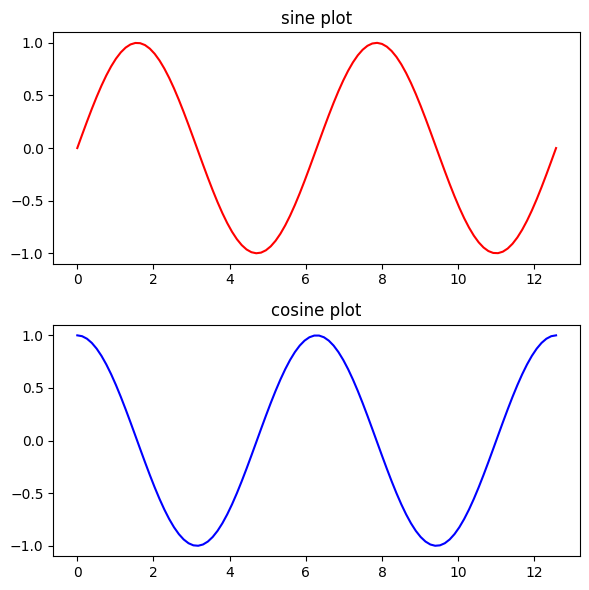

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))
axes[0].plot(x, y1, color='red')
axes[0].set_title('sine plot')
axes[1].plot(x, y2, color='blue')
axes[1].set_title('cosine plot')
fig.tight_layout()
plt.show()


依序填入 `2`、`1`、`y1`、`set_title`、`1`、`fig`、`show`。
`axes[0]` 控制上圖，`axes[1]` 控制下圖；`fig.tight_layout()` 調整整張畫布中子圖的間距。


<a id="exercise-6"></a>

## 小練習 6：比較兩組氣溫分布（程式填空）

來源：[matplotlib-資料視覺化.ipynb](./matplotlib-資料視覺化.ipynb)


### 題目

請將下方程式中的 `____` 補上，畫出左右兩張氣溫直方圖：

1. 依 `Rain` 分組：0 代表沒下雨，1 代表下雨，兩組都只取 `Temperature` 並排除缺失值。
2. 建立 1 列、2 欄的子圖，左圖畫沒下雨組，右圖畫下雨組。
3. 兩組使用相同的分箱邊界 `[15, 18, 21, 24, 27]`，也就是把氣溫分成四個區間，統計各區間的筆數。
4. 保留兩軸名稱與標題，最後顯示圖表。

每個 `____` 可以填入數字、方法名稱、變數或清單。完成填空後再執行。

```python
# 取出兩組氣溫，並排除缺失值
no_rain = df.loc[df['Rain'] == ____, 'Temperature'].____()
rain = df.loc[df['Rain'] == ____, 'Temperature'].____()

# 建立 1 列、2 欄的子圖
fig, axes = plt.subplots(____, ____, figsize=(10, 3))

# 畫直方圖：左右兩圖使用相同的分箱邊界
axes[0].____(____, bins=[15, 18, 21, 24, 27])
axes[1].____(____, bins=____)

axes[0].set(title='No rain', xlabel='Temperature (C)', ylabel='Count')
axes[1].set(title='Rain', xlabel='Temperature (C)', ylabel='Count')
plt.____()
```


### 參考答案


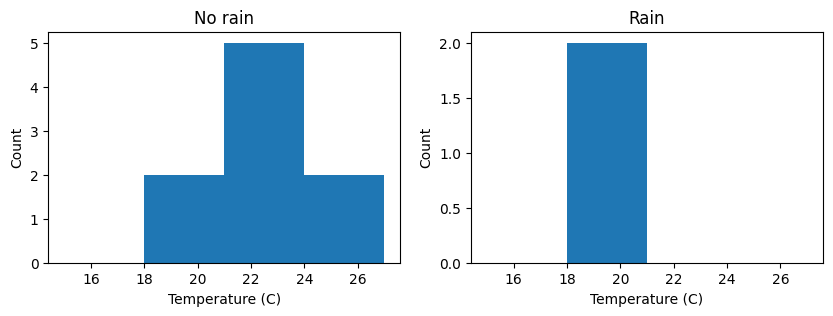

In [8]:
no_rain = df.loc[df['Rain'] == 0, 'Temperature'].dropna()
rain = df.loc[df['Rain'] == 1, 'Temperature'].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(no_rain, bins=[15, 18, 21, 24, 27])
axes[1].hist(rain, bins=[15, 18, 21, 24, 27])
axes[0].set(title='No rain', xlabel='Temperature (C)', ylabel='Count')
axes[1].set(title='Rain', xlabel='Temperature (C)', ylabel='Count')
plt.show()


`dropna()` 排除缺失氣溫；`hist()` 畫直方圖。兩組使用相同分箱邊界，每根長條表示該區間的筆數。
沒下雨組有 9 筆有效氣溫，下雨組只有 2 筆；比較時也要留意兩張圖的縱軸刻度可能不同。


<a id="exercise-7"></a>

## 小練習 7：加入是否下雨的相關係數熱圖（程式填空）

來源：[matplotlib-資料視覺化.ipynb](./matplotlib-資料視覺化.ipynb)


### 題目

請補完下方 `____`，將 `Temperature`、`Humidity`、`Rain` 三欄的相關係數畫成 3 × 3 熱圖。
格子內要顯示兩位小數，色階固定為 −1 到 1，並以 0 為中心。

`Rain` 是 0／1 指標，可以在本例中一起計算；結果只描述這份小型模擬資料的關聯。
完成後找出「氣溫與是否下雨」的格子，說明它是正相關還是負相關。

```python
# 選取三個欄位並計算相關係數
corr = df[['Temperature', 'Humidity', ____]].____()

# 顯示數值，保留兩位小數，固定色階範圍
sns.heatmap(____, annot=____, fmt='.2f', vmin=____, vmax=____, center=0, cmap='coolwarm')
plt.title('Weather feature correlation')
plt.tight_layout()
plt.____()
```


### 參考答案


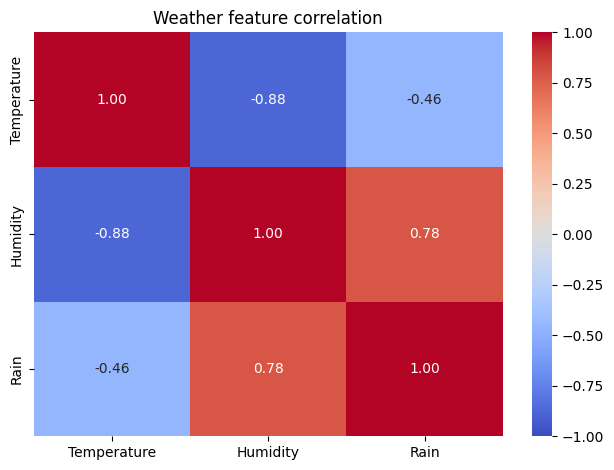

In [9]:
corr = df[['Temperature', 'Humidity', 'Rain']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.title('Weather feature correlation')
plt.tight_layout()
plt.show()


填入 `'Rain'`、`corr`、`corr`、`True`、`-1`、`1`、`show`。
氣溫與是否下雨呈負相關：在這份資料中，下雨樣本的氣溫傾向較低。
三欄都與自己完全相關，所以對角線為 1；矩陣上下對稱，交換兩個欄位不會改變相關係數。
氣溫有缺失值，各組欄位配對計算時的有效樣本數可能不同；少量模擬資料不能用來推論因果或一般天氣規律。


<a id="exercise-8"></a>

## 小練習 8：學習另一條直線（程式填空）

來源：[scikit-learn-基本功能.ipynb](./scikit-learn-基本功能.ipynb)


### 題目

請補上 `____`，用 `y = 3x + 2` 的資料訓練線性迴歸，再預測 `x = 5` 的結果，約需 3 分鐘。

1. 建立模型，讓它同時學習斜率與截距。
2. 用 `fit(X, y)` 訓練，再用 `predict(X)` 預測。
3. 執行後檢查斜率、截距與預測值是否符合原本的直線。

提示：`exercise_x` 的 shape 是 `(5, 1)`，代表 5 筆樣本、每筆 1 個特徵。
預測單筆資料也要保留二維格式：`[[數值]]`。

```python
# exercise_x = np.array([[0], [1], [2], [3], [4]])
# exercise_y = ____ * exercise_x + ____

# exercise_model = LinearRegression(fit_intercept=____)
# exercise_model.____(exercise_x, exercise_y)
# exercise_pred = exercise_model.____([[____]])

# print('斜率：', exercise_model.coef_)
# print('截距：', exercise_model.intercept_)
# print('x = 5 的預測：', exercise_pred[0, 0])
```


### 參考答案


In [10]:
exercise_x = np.array([[0], [1], [2], [3], [4]])
exercise_y = 3 * exercise_x + 2

exercise_model = LinearRegression(fit_intercept=True)
exercise_model.fit(exercise_x, exercise_y)
exercise_pred = exercise_model.predict([[5]])

print('斜率：', exercise_model.coef_)
print('截距：', exercise_model.intercept_)
print('x = 5 的預測：', exercise_pred[0, 0])


斜率： [[3.]]
截距： [2.]
x = 5 的預測： 17.0


依序填入 `3`、`2`、`True`、`fit`、`predict`、`5`。
學到的斜率約為 3、截距約為 2，所以 `x = 5` 的預測約為 **17**；浮點運算可能造成些微誤差。

`fit_intercept=True` 讓模型學習常數項 2。`fit()` 接收輸入和答案，`predict()` 只接收要預測的輸入。
這裡 `exercise_y` 是二維的 `(5, 1)`，因此單筆預測結果也是二維的 `(1, 1)`，用 `[0, 0]` 取出數值。


<a id="classroom-discussion"></a>

## 課堂互動：換個情境，你會怎麼判斷？

來源：scikit-learn-基本功能.ipynb


### 題目

以下不需要寫程式，請運用前面學到的概念說明理由，約需 3 分鐘。

1. **數字一定是數值特徵嗎？** 學校想預測學生的考試成績，資料中有學號 `2026001`、`2026002` 等，每人學號都不同。有人建議：「學號是數字，先標準化；不然就把每個學號做成 One-hot，模型就能預測新學生。」你認為這兩種處理是否合理？學號的數字大小或差距，真的代表學習能力的差異嗎？
2. **不同班級的標準化分數能直接比原始成績嗎？** 小明在甲班、小華在乙班，參加同一份考試。兩班分別用各自的平均數與標準差做標準化，兩人的標準化分數都是 `z = 1`。是否能因此認定兩人的原始分數相同？還需要知道哪些資訊？

請在下方以 `#` 註解作答，或先與同學口頭討論。


### 參考答案

1. 學號主要是識別身分的代碼，不是能力的測量值。數字相差 1，不代表能力相差一個單位；標準化只會改變尺度，不會讓它變成有意義的特徵。每人都有唯一學號時，One-hot 可能讓模型記住個別學生，卻難以由新學生的學號推論成績；即使編碼工具能處理新學號，也不代表它提供了預測資訊。因此這個情境通常先排除學號，改找與任務有關的特徵。
2. 不能。`z = 1` 只代表各自高於自己班級的平均值 1 個標準差。還需要兩班的平均數與標準差，才能用 $x=\mu+z\sigma$ 還原原始分數。例如甲班平均 60、標準差 10，小明是 70 分；乙班平均 75、標準差 5，小華則是 80 分。使用不同參考群體的標準化分數，不能直接當成原始分數比較。


<a id="other-fill-exercises"></a>

## 其他 NumPy／pandas 填空練習答案


### 練習 1：固定輸入的 Softmax（程式填空）

補完穩定 Softmax：先減去最大值，再取指數並除以總和。輸出保留六位小數。

請補上 `____`，保留固定資料與所有 print，不可直接寫死預期結果。NumPy 題請先匯入 `numpy as np`；pandas 題沿用教材讀入、尚未填補的原始 `df`。

**預期輸出（逐行比對）：**

```text
probabilities: [0.166667, 0.333333, 0.5]
sum: 1.0
```

```python
logits = np.log(np.array([1., 2., 3.]))
shifted = logits - logits.____()
exp_values = np.____(shifted)
probabilities = exp_values / exp_values.____()
print('probabilities:', np.round(probabilities, 6).tolist())
print('sum:', round(float(probabilities.sum()), 6))
```


#### 參考答案


In [11]:
logits = np.log(np.array([1., 2., 3.]))
shifted = logits - logits.max()
exp_values = np.exp(shifted)
probabilities = exp_values / exp_values.sum()
print('probabilities:', np.round(probabilities, 6).tolist())
print('sum:', round(float(probabilities.sum()), 6))


probabilities: [0.166667, 0.333333, 0.5]
sum: 1.0


依序填入 `max`、`exp`、`sum`。固定 logits，避免隨機輸入讓預期輸出改變。


### 練習 2：Linear Layer + ReLU（程式填空）

以矩陣乘法算出 z = W @ x + b，再把負值改成 0。請保留二維 shape。

請補上 `____`，保留固定資料與所有 print，不可直接寫死預期結果。NumPy 題請先匯入 `numpy as np`；pandas 題沿用教材讀入、尚未填補的原始 `df`。

**預期輸出（逐行比對）：**

```text
linear: [[4.0], [-4.0], [-3.0]]
relu: [[4.0], [0.0], [0.0]]
shape: (3, 1)
```

```python
x = np.array([[1.], [-2.]])
W = np.array([[2., -1.], [-1., 2.], [0., 0.]])
bias = np.array([[0.], [1.], [-3.]])
z = ____ @ ____ + ____
activation = z.copy()
activation[activation < ____] = ____
print('linear:', z.tolist())
print('relu:', activation.tolist())
print('shape:', activation.shape)
```


#### 參考答案


In [12]:
x = np.array([[1.], [-2.]])
W = np.array([[2., -1.], [-1., 2.], [0., 0.]])
bias = np.array([[0.], [1.], [-3.]])
z = W @ x + bias
activation = z.copy()
activation[activation < 0] = 0
print('linear:', z.tolist())
print('relu:', activation.tolist())
print('shape:', activation.shape)


linear: [[4.0], [-4.0], [-3.0]]
relu: [[4.0], [0.0], [0.0]]
shape: (3, 1)


依序填入 `W`、`x`、`bias`、`0`、`0`。ReLU 僅把負值改成 0。


### 練習：找出高於平均氣溫的日期（程式填空）

使用原始 df 的有效氣溫計算平均，找出嚴格高於平均的日期與氣溫。保留原列順序，平均及氣溫輸出保留兩位小數。

請補上 `____`，保留固定資料與所有 print，不可直接寫死預期結果。NumPy 題請先匯入 `numpy as np`；pandas 題沿用教材讀入、尚未填補的原始 `df`。

**預期輸出（逐行比對）：**

```text
mean_temperature: 21.64
days: [4, 5, 6, 10, 11, 12]
temperatures: [23.0, 24.5, 22.0, 22.5, 25.0, 23.5]
count: 6
```

```python
mean_temp = df['Temperature'].____()
above_mean = df.loc[df['Temperature'] > ____, [____, ____]]
print('mean_temperature:', round(float(mean_temp), 2))
print('days:', above_mean['Day'].tolist())
print('temperatures:', above_mean['Temperature'].round(2).tolist())
print('count:', len(____))
```


#### 參考答案


In [13]:
mean_temp = df['Temperature'].mean()
above_mean = df.loc[df['Temperature'] > mean_temp, ['Day', 'Temperature']]
print('mean_temperature:', round(float(mean_temp), 2))
print('days:', above_mean['Day'].tolist())
print('temperatures:', above_mean['Temperature'].round(2).tolist())
print('count:', len(above_mean))


mean_temperature: 21.64
days: [4, 5, 6, 10, 11, 12]
temperatures: [23.0, 24.5, 22.0, 22.5, 25.0, 23.5]
count: 6


依序填入 `mean`、`mean_temp`、`'Day'`、`'Temperature'`、`above_mean`。mean 忽略缺失氣溫，缺失值不會符合大於條件。


## scikit-learn 一般練習參考答案

## 練習

沿用前面的 Titanic `data/train.csv`。

### 練習 1：改善決策樹分類模型

請改進 `sklearn.tree.DecisionTreeClassifier` 模型分類效果，可以嘗試：

- 增加更多的輸入特徵
- 使用不同的前處理方法
- 調整超參數

### 練習 2：使用不同的模型

請使用不同的模型打敗使用 `sklearn.tree.DecisionTreeClassifier` 模型分類效果，可以嘗試課堂所提過的方法：

|模型|名稱|
|-|-|
|[`sklearn.naive_bayes`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.naive_bayes)|樸素貝氏分類器（Naive Bayes Classifier）|
|[`sklearn.svm`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.svm)|支援向量機（Support Vector Machines）|
|[`sklearn.neighbors`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.neighbors)|近鄰演算法（Nearest Neighbors）|
|[`sklearn.ensemble`](https://scikit-learn.org/stable/modules/classes.html?highlight=metric#module-sklearn.ensemble)|集合學習（Ensemble）|


### 練習 1 參考答案


In [14]:
# 練習 1 解答

# 匯入填補缺失值的工具
from sklearn.impute import SimpleImputer          
# 匯入 Label Encoder
from sklearn.preprocessing import LabelEncoder    
# 匯入決策樹模型
from sklearn.tree import DecisionTreeClassifier   
# 匯入準確度計算工具
from sklearn.metrics import accuracy_score        

train_df = pd.read_csv('./data/train.csv')

# 取出訓練資料需要分析的資料欄位
train_x = train_df[['Sex', 'Age', 'Fare']]        
# 取出訓練資料的答案
train_y = train_df['Survived']                    

# 數值型態資料前處理
# 創造 imputer 並設定填補策略
imputer = SimpleImputer(strategy='median')        
age = train_x['Age'].to_numpy().reshape(-1, 1)
# 根據資料學習需要填補的值
imputer.fit(age)                                  
# 填補缺失值
train_x['Age'] = imputer.transform(age)           

# 類別型態資料前處理
# 創造 Label Encoder
le = LabelEncoder()                               
# 給予每個類別一個數值
le.fit(train_x['Sex'])                            
# 轉換所有類別成為數值
train_x['Sex'] = le.transform(train_x['Sex'])     

# 創造決策樹模型
model = DecisionTreeClassifier(random_state=1012) 
# 訓練決策樹模型
model.fit(train_x, train_y)                       

# 確認模型是否訓練成功
pred_y = model.predict(train_x)                   
# 計算準確度
acc = accuracy_score(train_y, pred_y)             

# 輸出準確度
print('accuracy: {}'.format(acc))                 

accuracy: 0.9775533108866442


C:\Users\fzq10\AppData\Local\Temp\ipykernel_6952\3490407721.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_x['Age'] = imputer.transform(age)
C:\Users\fzq10\AppData\Local\Temp\ipykernel_6952\3490407721.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_x['Sex'] = le.transform(train_x['Sex'])


### 練習 2 參考答案


In [15]:
# 練習 2 解答

# 匯入填補缺失值的工具
from sklearn.impute import SimpleImputer          
# 匯入 Label Encoder
from sklearn.preprocessing import LabelEncoder    
# 匯入支援向量機模型
from sklearn.svm import SVC                       
# 匯入準確度計算工具
from sklearn.metrics import accuracy_score        

train_df = pd.read_csv('./data/train.csv')

# 取出訓練資料需要分析的資料欄位
train_x = train_df[['Sex', 'Age', 'Fare']]        
# 取出訓練資料的答案
train_y = train_df['Survived']                    

# 數值型態資料前處理
# 創造 imputer 並設定填補策略
imputer = SimpleImputer(strategy='median')        
age = train_x['Age'].to_numpy().reshape(-1, 1)
# 根據資料學習需要填補的值
imputer.fit(age)                                  
# 填補缺失值
train_x['Age'] = imputer.transform(age)           

# 類別型態資料前處理
# 創造 Label Encoder
le = LabelEncoder()                               
# 給予每個類別一個數值
le.fit(train_x['Sex'])                            
# 轉換所有類別成為數值
train_x['Sex'] = le.transform(train_x['Sex'])     

# 創造支援向量機模型
model = SVC(random_state=1012)                    
# 訓練支援向量機模型
model.fit(train_x, train_y)                       

# 確認模型是否訓練成功
pred_y = model.predict(train_x)                   
# 計算準確度
acc = accuracy_score(train_y, pred_y)             

# 輸出準確度
print('accuracy: {}'.format(acc))                 

accuracy: 0.6812570145903479


C:\Users\fzq10\AppData\Local\Temp\ipykernel_6952\1801632121.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_x['Age'] = imputer.transform(age)
C:\Users\fzq10\AppData\Local\Temp\ipykernel_6952\1801632121.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_x['Sex'] = le.transform(train_x['Sex'])
